# 04_seminar_demo: Locality Sensitive Hashing, from the lecture to MovieLens

CO5135 Big Data seminar demo. Notation follows the LSH lecture (HPC Lab, HCMUT, based on MMDS):
`b` bands, `r` rows per band, similarity `s`, candidate probability `1 - (1 - s^r)^b`.

1. Min-Hashing on the lecture example (7 shingles x 4 documents, 3 permutations)
2. Min-Hash property on real data: Pr[h(C1) = h(C2)] = Jaccard(C1, C2), users of MovieLens 1M as sets of movies
3. Banding on real data (r = 5, b = 20 from the lecture, and r = 3, b = 33): the S-curve measured vs. theory
4. Random hyperplanes (cosine): Pr[h(x) = h(y)] = 1 - θ/π
5. AND, OR and AND-OR constructions: shapes of the curves, picking r and b
6. Why Spark's BucketedRandomProjectionLSH (OR only) lost to SimHash banding (AND + OR) in the mini-project
7. LSH for Euclidean distance: projection on random lines, the (a/2, 2a, 1/2, 1/3)-sensitive family

**Input:** output of `00_prepare_data` (only `data/1m/train` is read, with pandas). No Spark, no internet needed.
Runs in a few minutes.

In [1]:
import os, glob, json, time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

SEED = 42
rng = np.random.default_rng(SEED)
hits = sorted(glob.glob("/kaggle/input/**/data/1m/train", recursive=True)) or sorted(glob.glob("data/1m/train"))
assert hits, "Khong thay du lieu. Kiem tra da Add Input output cua 00_prepare_data chua."
TRAIN_1M = hits[0]
os.makedirs("results", exist_ok=True)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})
def save(fig, name):
    fig.savefig(f"results/{name}.png"); print("Saved", f"results/{name}.png")
summary = {}

## 1. Min-Hashing on the lecture example

Input matrix: 7 shingles (rows) x 4 documents (columns). For a permutation π, h_π(C) is the smallest
permuted row number among the rows where column C has a 1. Three permutations give a 3 x 4 signature matrix.

In [2]:
M = np.array([[1, 0, 1, 0],
              [1, 0, 0, 1],
              [0, 1, 0, 1],
              [0, 1, 0, 1],
              [0, 1, 0, 1],
              [1, 0, 1, 0],
              [1, 0, 1, 0]])
perms = np.array([[2, 3, 7, 6, 1, 5, 4],      # pi(row 1..7), as on the slide
                  [4, 2, 1, 3, 6, 7, 5],
                  [3, 4, 7, 2, 6, 1, 5]])
sig = np.array([[p[M[:, c] == 1].min() for c in range(M.shape[1])] for p in perms])
print("Signature matrix:\n", sig)

def jaccard_cols(a, b):
    return (a & b).sum() / (a | b).sum()

rows = []
for i, j in [(0, 2), (1, 3), (0, 1), (2, 3)]:
    rows.append({"pair": f"C{i+1}-C{j+1}", "Jaccard (columns)": round(jaccard_cols(M[:, i], M[:, j]), 2),
                 "Signature agreement": round((sig[:, i] == sig[:, j]).mean(), 2)})
pd.DataFrame(rows)

Signature matrix:
 [[2 1 2 1]
 [2 1 4 1]
 [1 2 1 2]]


,pair,Jaccard (columns),Signature agreement
0,C1-C3,0.75,0.67
1,C2-C4,0.75,1.00
2,C1-C2,0.00,0.00
3,C3-C4,0.00,0.00


With only 3 permutations the agreement is a rough estimate (0.67 vs 0.75). With K = 100 hash functions the
estimate becomes accurate, as the next section shows on real data.

## 2. Min-Hash property on MovieLens 1M

Each user is a set of movies he or she rated. Jaccard(u, v) = |movies in common| / |movies in union|.
Instead of permutations we use K = 100 universal hash functions h(x) = ((a·x + b) mod p) mod N (lecture slide 32).

In [3]:
r1m = pd.read_parquet(TRAIN_1M, columns=["userId", "movieId"])
users = np.sort(r1m["userId"].unique()); movies = np.sort(r1m["movieId"].unique())
u_idx = np.searchsorted(users, r1m["userId"].to_numpy()); m_idx = np.searchsorted(movies, r1m["movieId"].to_numpy())
A = sp.csr_matrix((np.ones(len(r1m), dtype=np.float32), (u_idx, m_idx)), shape=(len(users), len(movies)))
A.data[:] = 1
n_users, n_movies = A.shape
sizes = np.asarray(A.sum(axis=1)).ravel()
print(f"Users: {n_users:,} | movies: {n_movies:,} | ratings: {A.nnz:,}")

# Jaccard chinh xac cho moi cap user (giao = A A^T, hop = |A| + |B| - giao)
t0 = time.time()
inter = (A @ A.T).tocoo()
mask = inter.row < inter.col
I, J, inter_v = inter.row[mask], inter.col[mask], inter.data[mask]
jac = inter_v / (sizes[I] + sizes[J] - inter_v)
total_pairs = n_users * (n_users - 1) // 2
print(f"Exact Jaccard for all {total_pairs:,} pairs in {time.time() - t0:.1f}s "
      f"({len(jac):,} pairs share at least one movie)")

Users: 6,580 | movies: 18,662 | ratings: 800,018
Exact Jaccard for all 21,644,910 pairs in 2.9s (17,973,842 pairs share at least one movie)


Min-Hash signatures (100 x 6,580) in 0.4s
Sampled 2,848 pairs | mean |estimate - Jaccard| = 0.028, 95th percentile = 0.074 (theory: std <= 0.05 for K = 100)
Saved results/seminar_minhash_estimate.png


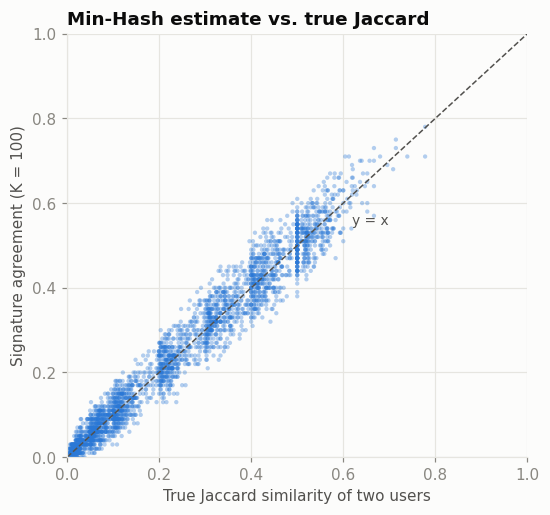

In [4]:
K_HASH, P = 100, 2_147_483_647                 # so ham hash, so nguyen to > so phim
a = rng.integers(1, P, K_HASH); b_ = rng.integers(0, P, K_HASH)
H = ((a[:, None] * np.arange(n_movies)[None, :] + b_[:, None]) % P).astype(np.int64)   # K x n_movies

t0 = time.time()
SIG = np.empty((K_HASH, n_users), dtype=np.int64)
indptr, indices = A.indptr, A.indices
for u in range(n_users):
    SIG[:, u] = H[:, indices[indptr[u]:indptr[u + 1]]].min(axis=1)
print(f"Min-Hash signatures ({K_HASH} x {n_users:,}) in {time.time() - t0:.1f}s")

# Lay mau cap theo tung khoang Jaccard de thay ca vung Jaccard cao (rat hiem)
bins = np.array([0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.01])
samp = []
for lo, hi in zip(bins[:-1], bins[1:]):
    idx = np.where((jac >= lo) & (jac < hi))[0]
    if len(idx):
        samp.append(rng.choice(idx, min(400, len(idx)), replace=False))
samp = np.concatenate(samp)
est = (SIG[:, I[samp]] == SIG[:, J[samp]]).mean(axis=0)
err = np.abs(est - jac[samp])
print(f"Sampled {len(samp):,} pairs | mean |estimate - Jaccard| = {err.mean():.3f}, "
      f"95th percentile = {np.quantile(err, 0.95):.3f} (theory: std <= 0.05 for K = 100)")
summary["minhash"] = {"users": int(n_users), "K": K_HASH, "mean_abs_err": round(float(err.mean()), 4)}

fig, ax = plt.subplots(figsize=(5.4, 5))
ax.scatter(jac[samp], est, s=8, color=BLUE, alpha=0.35, edgecolor="none")
ax.plot([0, 1], [0, 1], color=INK2, linewidth=1, linestyle="--")
ax.text(0.62, 0.55, "y = x", color=INK2, fontsize=9)
ax.set_title("Min-Hash estimate vs. true Jaccard")
ax.set_xlabel("True Jaccard similarity of two users")
ax.set_ylabel(f"Signature agreement (K = {K_HASH})")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
save(fig, "seminar_minhash_estimate"); plt.show()

## 3. Banding on real data: the S-curve, measured

Split the signatures into b bands of r rows. Two users become a candidate pair if they are identical in at
least one band. Theory: Pr[candidate] = 1 - (1 - s^r)^b, steepest near t ≈ (1/b)^(1/r).

Two settings: the lecture example (r = 5, b = 20, t ≈ 0.55) and r = 3, b = 33 (t ≈ 0.31), which puts the
threshold where MovieLens users actually are (most user pairs have Jaccard below 0.3).
For the measurement we test every pair that shares at least one movie (pairs with Jaccard 0 can never collide);
a real system finds the same pairs by hashing each band into buckets, as done with Spark in 02_als_bf_lsh.

Share of user pairs by Jaccard: {'>= 0.1': '5.8902%', '>= 0.2': '0.6550%', '>= 0.3': '0.1179%', '>= 0.5': '0.0029%'}
r=5, b=20 (t = 0.55): candidates 6,219 = 0.029% of all pairs | pairs with Jaccard >= t: 180, found 73.3% | 29.9s
r=3, b=33 (t = 0.31): candidates 232,878 = 1.076% of all pairs | pairs with Jaccard >= t: 20,421, found 81.8% | 39.6s
Saved results/seminar_scurve_measured.png


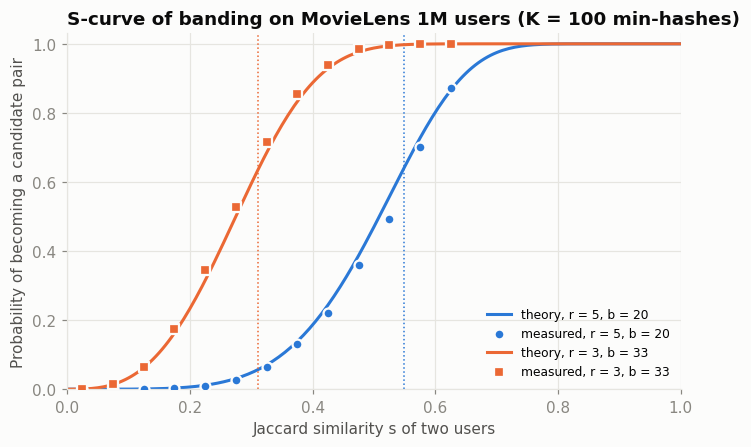

,s,1-(1-s^5)^20
0,0.2,0.0064
1,0.3,0.0475
2,0.4,0.1860
3,0.5,0.4701
4,0.6,0.8019
5,0.7,0.9748
6,0.8,0.9996


In [5]:
def candidate_mask(SIG, b, r, I, J, block=4_000_000):
    """True for pairs (I[k], J[k]) whose signatures are identical in at least one band."""
    out = np.zeros(len(I), dtype=bool)
    for s0 in range(0, len(I), block):
        ii, jj = I[s0:s0 + block], J[s0:s0 + block]
        m = np.zeros(len(ii), dtype=bool)
        for k in range(b):
            band = SIG[k * r:(k + 1) * r]
            m |= (band[:, ii] == band[:, jj]).all(axis=0)
        out[s0:s0 + block] = m
    return out

print("Share of user pairs by Jaccard:", {f">= {t}": f"{(jac >= t).sum() / total_pairs:.4%}" for t in [0.1, 0.2, 0.3, 0.5]})
edges = np.linspace(0, 1, 21); mid = (edges[:-1] + edges[1:]) / 2
s = np.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(7.2, 4.2))
summary["banding"] = []
for (r, b), color in [((5, 20), BLUE), ((3, 33), ORANGE)]:
    t0 = time.time()
    is_cand = candidate_mask(SIG, b, r, I, J)
    t_thr = (1 / b) ** (1 / r)
    emp = [is_cand[(jac >= lo) & (jac < hi)].mean() if ((jac >= lo) & (jac < hi)).sum() >= 20 else np.nan
           for lo, hi in zip(edges[:-1], edges[1:])]
    above = jac >= t_thr
    rec = float(is_cand[above].mean()) if above.any() else float("nan")
    print(f"r={r}, b={b} (t = {t_thr:.2f}): candidates {is_cand.sum():,} = {is_cand.sum() / total_pairs:.3%} of all pairs | "
          f"pairs with Jaccard >= t: {above.sum():,}, found {rec:.1%} | {time.time() - t0:.1f}s")
    summary["banding"].append({"r": r, "b": b, "t": round(t_thr, 3),
                               "cand_pct_of_all_pairs": round(100 * is_cand.sum() / total_pairs, 4),
                               "pairs_above_t": int(above.sum()), "recall_above_t": round(rec, 4)})
    ax.plot(s, 1 - (1 - s ** r) ** b, color=color, linewidth=2, label=f"theory, r = {r}, b = {b}")
    ax.scatter(mid, emp, s=42, color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3, marker="o" if r == 5 else "s",
               label=f"measured, r = {r}, b = {b}")
    ax.axvline(t_thr, color=color, linewidth=1, linestyle=":")
ax.set_title("S-curve of banding on MovieLens 1M users (K = 100 min-hashes)")
ax.set_xlabel("Jaccard similarity s of two users")
ax.set_ylabel("Probability of becoming a candidate pair")
ax.set_xlim(0, 1); ax.set_ylim(0, 1.03)
ax.legend(frameon=False, loc="lower right", fontsize=8)
save(fig, "seminar_scurve_measured"); plt.show()

# Bang trong slide 50: b = 20, r = 5
pd.DataFrame({"s": [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8],
              "1-(1-s^5)^20": [round(1 - (1 - x ** 5) ** 20, 4) for x in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]]})

## 4. Random hyperplanes for cosine distance

h_v(x) = +1 if v·x ≥ 0, else -1. For two vectors at angle θ: Pr[h(x) = h(y)] = 1 - θ/π (lecture slides 89-91).
Check with random 40-dimensional vectors (the ALS rank used in the mini-project).

Saved results/seminar_hyperplanes.png


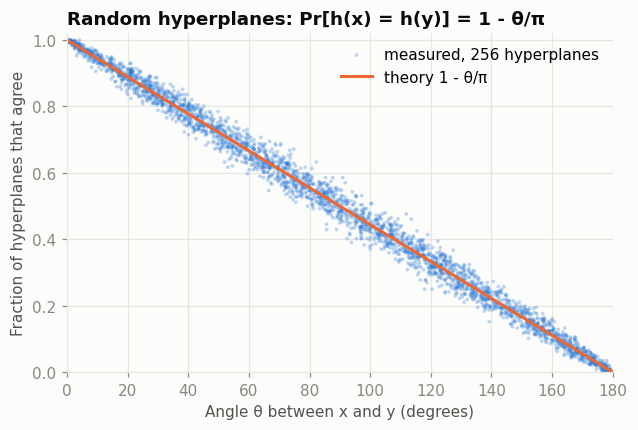

In [6]:
d, n_pairs, n_planes = 40, 3000, 256
X = rng.standard_normal((n_pairs, d))
target = rng.uniform(0, np.pi, n_pairs)                           # goc mong muon
Z = rng.standard_normal((n_pairs, d)); Z -= (Z * X).sum(1, keepdims=True) / (X * X).sum(1, keepdims=True) * X
Xn = X / np.linalg.norm(X, axis=1, keepdims=True); Zn = Z / np.linalg.norm(Z, axis=1, keepdims=True)
Y = np.cos(target)[:, None] * Xn + np.sin(target)[:, None] * Zn   # vector cach X dung goc target
V = rng.standard_normal((d, n_planes))
agree = ((Xn @ V >= 0) == (Y @ V >= 0)).mean(axis=1)

fig, ax = plt.subplots(figsize=(6.4, 4))
ax.scatter(np.degrees(target), agree, s=6, color=BLUE, alpha=0.3, edgecolor="none", label=f"measured, {n_planes} hyperplanes")
th = np.linspace(0, np.pi, 100)
ax.plot(np.degrees(th), 1 - th / np.pi, color=ORANGE, linewidth=2, label="theory 1 - θ/π")
ax.set_title("Random hyperplanes: Pr[h(x) = h(y)] = 1 - θ/π")
ax.set_xlabel("Angle θ between x and y (degrees)")
ax.set_ylabel("Fraction of hyperplanes that agree")
ax.set_xlim(0, 180); ax.set_ylim(0, 1.02)
ax.legend(frameon=False)
save(fig, "seminar_hyperplanes"); plt.show()
summary["hyperplanes_mean_abs_err"] = round(float(np.abs(agree - (1 - target / np.pi)).mean()), 4)

## 5. AND, OR, and AND-OR constructions

- AND (r rows, 1 band): p → p^r. Lowers every probability.
- OR (1 row, b bands): p → 1 - (1 - p)^b. Raises every probability.
- AND then OR: p → 1 - (1 - p^r)^b. Low probabilities go down, high ones go up: the S-curve.

Saved results/seminar_and_or.png


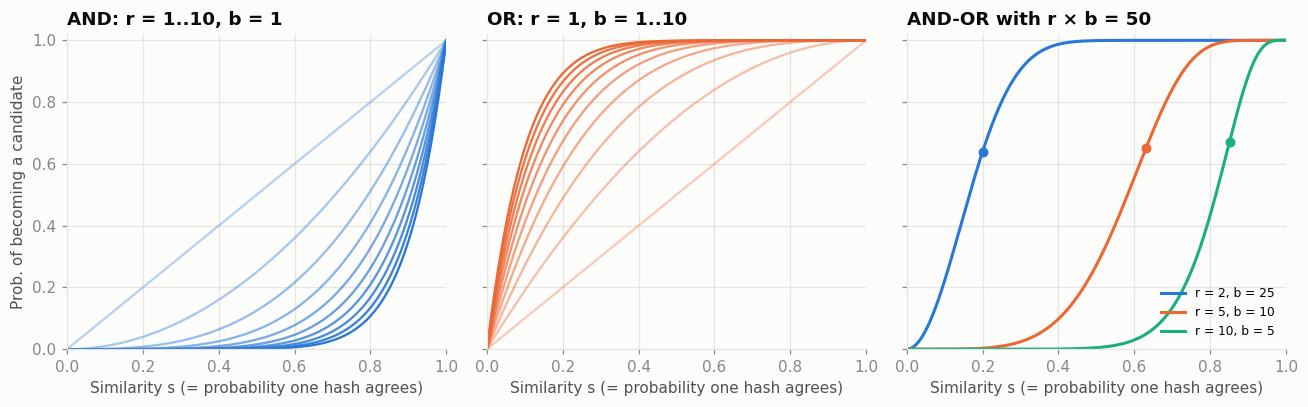

In [7]:
p = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for r in range(1, 11):
    axes[0].plot(p, p ** r, color=BLUE, alpha=0.25 + 0.075 * r, linewidth=1.5)
axes[0].set_title("AND: r = 1..10, b = 1")
for b in range(1, 11):
    axes[1].plot(p, 1 - (1 - p) ** b, color=ORANGE, alpha=0.25 + 0.075 * b, linewidth=1.5)
axes[1].set_title("OR: r = 1, b = 1..10")
for (r, b), c in zip([(2, 25), (5, 10), (10, 5)], [BLUE, ORANGE, AQUA]):
    axes[2].plot(p, 1 - (1 - p ** r) ** b, color=c, linewidth=2, label=f"r = {r}, b = {b}")
    t = (1 / b) ** (1 / r)
    axes[2].scatter([t], [1 - (1 - t ** r) ** b], color=c, s=30, zorder=3)
axes[2].set_title("AND-OR with r × b = 50")
axes[2].legend(frameon=False, loc="lower right", fontsize=8)
for ax in axes:
    ax.set_xlabel("Similarity s (= probability one hash agrees)")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
axes[0].set_ylabel("Prob. of becoming a candidate")
fig.tight_layout()
save(fig, "seminar_and_or"); plt.show()

## 6. Mini-project link: why Spark BRP lost to SimHash banding

In the mini-project (02_als_bf_lsh, 1M subset, 4,885 movies, ALS rank 40):

| Method | Candidate pairs | Recall@10 | Time | vs. brute-force |
|---|---|---|---|---|
| Spark brute-force | 100% | 1.00 | 82.7 s | 1.00x |
| Spark BRP, bucketLength 0.05, 10 tables | 82% | 0.94 | 511 s | 0.16x |
| SimHash banding, r = 12, b = 20 | 52% | 0.94 | 50.6 s | 1.63x |

Spark's `BucketedRandomProjectionLSH` uses **one** projection per hash table and joins tables with OR only:
p → 1 - (1 - p)^L. There is no AND step, so the curve is concave and cannot separate neighbors from random pairs.
SimHash banding uses r random hyperplanes per band (AND) and b bands (OR), giving the S-curve in cosine space.
The plot puts the curves on the same x axis: cosine similarity of two movie vectors.

Saved results/seminar_or_vs_andor.png


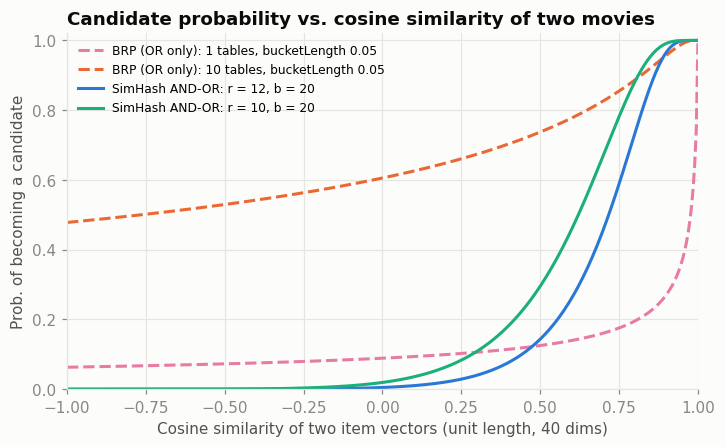

In [8]:
from math import erf, sqrt, pi, exp
D, W = 40, 0.05                      # ALS rank, bucketLength cua cau hinh BRP tot nhat
def p_brp(cos_sim):
    """Collision prob. of ONE bucketed random projection (width W) for unit vectors in D dims (Datar et al. 2004)."""
    d = np.sqrt(np.maximum(2 - 2 * cos_sim, 1e-12)); sigma = d / np.sqrt(D); u = W / sigma
    Phi = 0.5 * (1 + np.vectorize(erf)(u / sqrt(2)))
    return (2 * Phi - 1) - 2 / (u * sqrt(2 * pi)) * (1 - np.exp(-u ** 2 / 2))

c = np.linspace(-1, 1, 401)
p_hyper = 1 - np.arccos(c) / np.pi                      # 1 bit SimHash
fig, ax = plt.subplots(figsize=(7.4, 4.2))
for L, color in [(1, MAGENTA), (10, ORANGE)]:
    ax.plot(c, 1 - (1 - p_brp(c)) ** L, color=color, linestyle="--", linewidth=2,
            label=f"BRP (OR only): {L} tables, bucketLength {W}")
for (r, b), color in [((12, 20), BLUE), ((10, 20), AQUA)]:
    ax.plot(c, 1 - (1 - p_hyper ** r) ** b, color=color, linewidth=2, label=f"SimHash AND-OR: r = {r}, b = {b}")
ax.set_title("Candidate probability vs. cosine similarity of two movies")
ax.set_xlabel("Cosine similarity of two item vectors (unit length, 40 dims)")
ax.set_ylabel("Prob. of becoming a candidate")
ax.set_xlim(-1, 1); ax.set_ylim(0, 1.02)
ax.legend(frameon=False, loc="upper left", fontsize=8)
save(fig, "seminar_or_vs_andor"); plt.show()

Reading the plot: the BRP curves rise slowly and stay far from 0 for unrelated movies, so many useless pairs
become candidates. Adding tables (OR) lifts the whole curve: recall goes up but so do false positives.
The SimHash AND-OR curves stay near 0 for low cosine and jump close to 1 for high cosine: this is the step that
the AND construction makes possible.

## 7. LSH for Euclidean distance: projection on random lines

Hash = index of the bucket (width a) that contains the projection of the point on a random line.
Lecture claim: if d ≤ a/2 then Pr[same bucket] ≥ 1/2; if d ≥ 2a then Pr[same bucket] ≤ 1/3,
so the family is (a/2, 2a, 1/2, 1/3)-sensitive. Monte Carlo check in 2D with a random offset of the grid.

Saved results/seminar_euclidean.png


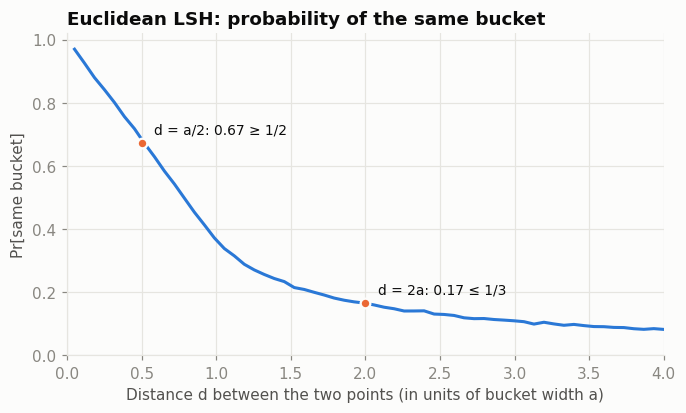

In [9]:
a_w, trials = 1.0, 20000
ratios = np.linspace(0.05, 4, 60)
prob = []
for ratio in ratios:
    ang = rng.uniform(0, np.pi, trials)                 # goc giua doan thang va duong chieu
    proj = ratio * a_w * np.abs(np.cos(ang))            # khoang cach sau khi chieu
    off = rng.uniform(0, a_w, trials)                   # do lech ngau nhien cua luoi bucket
    prob.append(np.mean(np.floor(off / a_w) == np.floor((off + proj) / a_w)))
prob = np.array(prob)
p_half = prob[np.argmin(np.abs(ratios - 0.5))]; p_two = prob[np.argmin(np.abs(ratios - 2))]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ratios, prob, color=BLUE, linewidth=2)
for x0, y0, txt in [(0.5, p_half, f"d = a/2: {p_half:.2f} ≥ 1/2"), (2, p_two, f"d = 2a: {p_two:.2f} ≤ 1/3")]:
    ax.scatter([x0], [y0], color=ORANGE, s=40, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.annotate(txt, (x0, y0), xytext=(8, 6), textcoords="offset points", color=INK, fontsize=9)
ax.set_title("Euclidean LSH: probability of the same bucket")
ax.set_xlabel("Distance d between the two points (in units of bucket width a)")
ax.set_ylabel("Pr[same bucket]")
ax.set_xlim(0, 4); ax.set_ylim(0, 1.02)
save(fig, "seminar_euclidean"); plt.show()
summary["euclidean"] = {"p_at_half_a": round(float(p_half), 3), "p_at_2a": round(float(p_two), 3)}

In [10]:
with open("results/seminar_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "minhash": {
    "users": 6580,
    "K": 100,
    "mean_abs_err": 0.0284
  },
  "banding": [
    {
      "r": 5,
      "b": 20,
      "t": 0.549,
      "cand_pct_of_all_pairs": 0.0287,
      "pairs_above_t": 180,
      "recall_above_t": 0.7333
    },
    {
      "r": 3,
      "b": 33,
      "t": 0.312,
      "cand_pct_of_all_pairs": 1.0759,
      "pairs_above_t": 20421,
      "recall_above_t": 0.8182
    }
  ],
  "hyperplanes_mean_abs_err": 0.0195,
  "euclidean": {
    "p_at_half_a": 0.671,
    "p_at_2a": 0.165
  }
}
